## Configuration

In [1]:
import os
import random
import numpy as np
import torch


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

In [2]:
import dataclasses
from pathlib import Path
from typing import Optional


@dataclasses.dataclass
class CMConfig:
    data_root: str = "/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset"

    n_fft: int = 1724
    win_length: int = 1724
    hop_length: int = 130
    window_fn: str = "blackman"
    num_frames: int = 600

    dropout_p: float = 0.75

    batch_size: int = 8
    lr: float = 3e-4
    betas: tuple = (0.9, 0.999)
    eps: float = 1e-8
    lr_decay_epochs: int = 10
    lr_decay_factor: float = 0.5
    num_epochs: int = 13

    monitor_size: Optional[int] = None
    early_stop_eer: float = 6.4
    early_stop_patience: int = 4
    min_epoch_for_best: int = 3

    num_workers: int = 4
    seed: int = 0
    device: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    checkpoint_dir: str = "./checkpoints"


config = CMConfig()
set_seed(config.seed)

## ASVspoof 2019 Dataset Analysis

In [3]:
LA_ROOT = Path(config.data_root) / "LA" / "LA"
PA_ROOT = Path(config.data_root) / "PA" / "PA"

print("Contents LA/LA:")
for p in sorted(LA_ROOT.iterdir()):
    print("  —", p.name)

Contents LA/LA:
  — ASVspoof2019_LA_asv_protocols
  — ASVspoof2019_LA_asv_scores
  — ASVspoof2019_LA_cm_protocols
  — ASVspoof2019_LA_dev
  — ASVspoof2019_LA_eval
  — ASVspoof2019_LA_train
  — README.LA.txt


In [4]:
print("Contents ASVspoof2019_LA_cm_protocols:")
for p in sorted((LA_ROOT / "ASVspoof2019_LA_cm_protocols").iterdir()):
    print("  —", p.name)

print("\nContents ASVspoof2019_LA_train:")
for p in sorted((LA_ROOT / "ASVspoof2019_LA_train").iterdir()):
    print("  —", p.name)

print("\nContents ASVspoof2019_LA_train/flac:")
for p in sorted((LA_ROOT / "ASVspoof2019_LA_train" / "flac").iterdir())[:5]:
    print("  —", p.name)

print("\nContents ASVspoof2019_LA_dev:")
for p in sorted((LA_ROOT / "ASVspoof2019_LA_dev").iterdir()):
    print("  —", p.name)

print("\nContents ASVspoof2019_LA_dev/flac:")
for p in sorted((LA_ROOT / "ASVspoof2019_LA_dev" / "flac").iterdir())[:5]:
    print("  —", p.name)

print("\nContents ASVspoof2019_LA_eval:")
for p in sorted((LA_ROOT / "ASVspoof2019_LA_eval").iterdir()):
    print("  —", p.name)

print("\nContents ASVspoof2019_LA_eval/flac:")
for p in sorted((LA_ROOT / "ASVspoof2019_LA_eval" / "flac").iterdir())[:5]:
    print("  —", p.name)


Contents ASVspoof2019_LA_cm_protocols:
  — ASVspoof2019.LA.cm.dev.trl.txt
  — ASVspoof2019.LA.cm.eval.trl.txt
  — ASVspoof2019.LA.cm.train.trn.txt

Contents ASVspoof2019_LA_train:
  — LICENSE.txt
  — flac

Contents ASVspoof2019_LA_train/flac:
  — LA_T_1000137.flac
  — LA_T_1000406.flac
  — LA_T_1000648.flac
  — LA_T_1000824.flac
  — LA_T_1001074.flac

Contents ASVspoof2019_LA_dev:
  — LICENSE.txt
  — flac

Contents ASVspoof2019_LA_dev/flac:
  — LA_D_1000265.flac
  — LA_D_1000752.flac
  — LA_D_1001095.flac
  — LA_D_1002130.flac
  — LA_D_1002200.flac

Contents ASVspoof2019_LA_eval:
  — LICENSE.txt
  — flac

Contents ASVspoof2019_LA_eval/flac:
  — LA_E_1000147.flac
  — LA_E_1000273.flac
  — LA_E_1000791.flac
  — LA_E_1000841.flac
  — LA_E_1000989.flac


In [5]:
for split in ["train", "dev", "eval"]:
    flac_path = LA_ROOT / f"ASVspoof2019_LA_{split}" / "flac"
    n_files = len(os.listdir(flac_path))
    print(f"{split:}: {n_files:} files")

train: 25380 files
dev: 24986 files
eval: 71933 files


In [6]:
protocol_dir = LA_ROOT / "ASVspoof2019_LA_cm_protocols"

flac_dir = {
    "train": LA_ROOT / "ASVspoof2019_LA_train" / "flac",
    "dev": LA_ROOT / "ASVspoof2019_LA_dev" / "flac",
    "eval": LA_ROOT / "ASVspoof2019_LA_eval" / "flac",
}

protocol_path = {
    "train": protocol_dir / "ASVspoof2019.LA.cm.train.trn.txt",
    "dev": protocol_dir / "ASVspoof2019.LA.cm.dev.trl.txt",
    "eval": protocol_dir / "ASVspoof2019.LA.cm.eval.trl.txt",
}

In [7]:
import pandas as pd

COLUMNS = ["speaker_id", "audio_filename", "-", "system_id", "key"]

for split, path in protocol_path.items():
    print(f"Protocol: {split.upper()} ({path.name})")    
    df_sample = pd.read_csv(path, sep=r"\s+", header=None, names=COLUMNS, nrows=5)
    
    display(df_sample)
    print("\n")

Protocol: TRAIN (ASVspoof2019.LA.cm.train.trn.txt)


,speaker_id,audio_filename,-,system_id,key
0,LA_0079,LA_T_1138215,-,-,bonafide
1,LA_0079,LA_T_1271820,-,-,bonafide
2,LA_0079,LA_T_1272637,-,-,bonafide
3,LA_0079,LA_T_1276960,-,-,bonafide
4,LA_0079,LA_T_1341447,-,-,bonafide




Protocol: DEV (ASVspoof2019.LA.cm.dev.trl.txt)


,speaker_id,audio_filename,-,system_id,key
0,LA_0069,LA_D_1047731,-,-,bonafide
1,LA_0069,LA_D_1105538,-,-,bonafide
2,LA_0069,LA_D_1125976,-,-,bonafide
3,LA_0069,LA_D_1293230,-,-,bonafide
4,LA_0069,LA_D_1340209,-,-,bonafide




Protocol: EVAL (ASVspoof2019.LA.cm.eval.trl.txt)


,speaker_id,audio_filename,-,system_id,key
0,LA_0039,LA_E_2834763,-,A11,spoof
1,LA_0014,LA_E_8877452,-,A14,spoof
2,LA_0040,LA_E_6828287,-,A16,spoof
3,LA_0022,LA_E_6977360,-,A09,spoof
4,LA_0031,LA_E_5932896,-,A13,spoof


In [8]:
def protocol(path) -> pd.DataFrame:
    rows = []
    with open(path, "r") as f:
        for line in f:
            
            speaker_id, audio_filename, _, system_id, key = line.split()
            label = 0 if key == "bonafide" else 1
            
            rows.append({
                "speaker_id": speaker_id,
                "audio_filename": audio_filename,
                "system_id": system_id,
                "key": key,
                "target": label
            })
            
    return pd.DataFrame(rows)

train_df = protocol(protocol_path["train"])
dev_df = protocol(protocol_path["dev"])
eval_df = protocol(protocol_path["eval"])

print(f"Shape (Train, Dev, Eval): {train_df.shape}, {dev_df.shape}, {eval_df.shape}\n")

eval_df.head()

Shape (Train, Dev, Eval): (25380, 5), (24844, 5), (71237, 5)



,speaker_id,audio_filename,system_id,key,target
0,LA_0039,LA_E_2834763,A11,spoof,1
1,LA_0014,LA_E_8877452,A14,spoof,1
2,LA_0040,LA_E_6828287,A16,spoof,1
3,LA_0022,LA_E_6977360,A09,spoof,1
4,LA_0031,LA_E_5932896,A13,spoof,1


In [9]:
for split_name, split_df in [("train", train_df), ("dev", dev_df), ("eval", eval_df)]:
    counts = split_df["target"].value_counts().sort_index()
    n_bonafide, n_spoof = int(counts[0]), int(counts[1])
    print(f"{split_name:5s}: bonafide {n_bonafide:6d} | spoof {n_spoof:6d}")

train: bonafide   2580 | spoof  22800
dev  : bonafide   2548 | spoof  22296
eval : bonafide   7355 | spoof  63882


## STFT Dataset and DataLoader

In [10]:
import torchaudio
from torch.utils.data import Dataset, DataLoader


class STFTDataset(Dataset):

    def __init__(self, protocol_df, flac_dir, config, train: bool):
        self.df = protocol_df.reset_index(drop=True)
        self.flac_dir = Path(flac_dir)
        self.config = config
        self.train = train

        window_fns = {"blackman": torch.blackman_window, "hann": torch.hann_window}
        self.spectrogram = torchaudio.transforms.Spectrogram(
            n_fft=config.n_fft,
            win_length=config.win_length,
            hop_length=config.hop_length,
            window_fn=window_fns[config.window_fn],
            power=2.0,
        )

    
    def __len__(self):
        return len(self.df)

    
    def _compute_spectrogram(self, audio_filename: str) -> np.ndarray:
        wav_path = self.flac_dir / f"{audio_filename}.flac"
        waveform, sr = torchaudio.load(wav_path)
        waveform = waveform.squeeze(0)

        power_spec = self.spectrogram(waveform)
        log_spec = torch.log(power_spec.clamp_min(1e-10)).numpy().astype(np.float32)

        return log_spec

    def _crop_or_pad(self, spec: np.ndarray) -> np.ndarray:
        num_frames = self.config.num_frames
        _, total_frames = spec.shape

        if total_frames >= num_frames:
            start = np.random.randint(0, total_frames - num_frames + 1) if self.train else 0
            return spec[:, start:start + num_frames]

        pad_width = num_frames - total_frames
        return np.pad(spec, ((0, 0), (0, pad_width)), mode="wrap")

    def __getitem__(self, index):
        row = self.df.iloc[index]
        audio_filename = row["audio_filename"]

        spec = self._compute_spectrogram(audio_filename)
        spec = self._crop_or_pad(spec)
        spec = torch.from_numpy(spec).unsqueeze(0)

        target = int(row["target"])

        return spec, target, audio_filename

In [11]:
train_dataset = STFTDataset(train_df, flac_dir["train"], config, train=True)
eval_dataset = STFTDataset(eval_df, flac_dir["eval"], config, train=False)

monitor_frac = min((config.monitor_size or len(eval_df)) / len(eval_df), 1.0)
monitor_df = eval_df.groupby("system_id", group_keys=False).sample(
    frac=monitor_frac, random_state=config.seed,
).sort_index()
monitor_dataset = STFTDataset(monitor_df, flac_dir["eval"], config, train=False)

train_loader = DataLoader(
    train_dataset,
    batch_size=config.batch_size,
    shuffle=True,
    num_workers=config.num_workers,
    pin_memory=True,
    persistent_workers=True,
    drop_last=True,
)

monitor_loader = DataLoader(
    monitor_dataset,
    batch_size=config.batch_size,
    shuffle=False,
    num_workers=config.num_workers,
    pin_memory=True,
    persistent_workers=True,
)

eval_loader = DataLoader(
    eval_dataset,
    batch_size=config.batch_size,
    shuffle=False,
    num_workers=config.num_workers,
    pin_memory=True,
    persistent_workers=False,
)

print(f"train: {len(train_dataset)} | monitor: {len(monitor_dataset)} | eval: {len(eval_dataset)}")

train: 25380 | monitor: 71237 | eval: 71237


In [12]:
batch_spec, batch_target, batch_audio_filename = next(iter(train_loader))

_ = next(iter(train_loader))
_ = next(iter(monitor_loader))

print("spec shape:", batch_spec.shape, batch_spec.dtype)
print("targets:", batch_target[:10])
print("audio_filenames:", batch_audio_filename[:3])

spec shape: torch.Size([8, 1, 863, 600]) torch.float32
targets: tensor([1, 1, 1, 1, 1, 1, 1, 0])
audio_filenames: ('LA_T_4927390', 'LA_T_8083854', 'LA_T_8497562')


## LCNN Model

In [13]:
import torch.nn as nn

class MFM(nn.Module):
    def __init__(self):
        super().__init__()
    
    def forward(self, x):
        a, b = torch.chunk(x, 2, dim=1)
        return torch.maximum(a, b)

In [14]:
class LCNN(nn.Module):

    def __init__(self, num_classes: int = 2, dropout_p: float = 0.75):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=5, stride=1, padding=2),
            MFM(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(32, 64, kernel_size=1, stride=1),
            MFM(),
            nn.BatchNorm2d(32),
            nn.Conv2d(32, 96, kernel_size=3, stride=1, padding=1),
            MFM(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.BatchNorm2d(48),
            nn.Conv2d(48, 96, kernel_size=1, stride=1),
            MFM(),
            nn.BatchNorm2d(48),
            nn.Conv2d(48, 128, kernel_size=3, stride=1, padding=1),
            MFM(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(64, 128, kernel_size=1, stride=1),
            MFM(),
            nn.BatchNorm2d(64),
            nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1),
            MFM(),
            nn.BatchNorm2d(32),
            nn.Conv2d(32, 64, kernel_size=1, stride=1),
            MFM(),
            nn.BatchNorm2d(32),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            MFM(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self.flatten_dim = 53 * 37 * 32

        self.fc1 = nn.Linear(self.flatten_dim, 160)
        self.mfm_fc = MFM()
        self.dropout = nn.Dropout(p=dropout_p)
        self.bn_fc = nn.BatchNorm1d(80)
        self.fc2 = nn.Linear(80, num_classes)

    def forward(self, x, return_embedding: bool = False):
        x = self.features(x)
        x = x.flatten(1)
        x = self.fc1(x)
        x = self.mfm_fc(x)
        x = self.dropout(x)
        x = self.bn_fc(x)

        embedding = x

        if return_embedding:
            return embedding
        return self.fc2(x)

In [15]:
def _init_weights(module: nn.Module):
    if isinstance(module, (nn.Conv2d, nn.Linear)):
        nn.init.kaiming_normal_(module.weight, nonlinearity="relu")
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, (nn.BatchNorm1d, nn.BatchNorm2d)):
        nn.init.ones_(module.weight)
        nn.init.zeros_(module.bias)


model = LCNN(num_classes=2, dropout_p=config.dropout_p).to(config.device)
model.apply(_init_weights)

n_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {n_params:,}")

Total parameters: 10,198,818


In [16]:
model.eval()
with torch.no_grad():
    test = model(batch_spec.to(config.device))

print("test:", test.shape)
print("test", test[:5])

test: torch.Size([8, 2])
test tensor([[  26.7252,  339.0467],
        [  -0.7238,  486.3532],
        [-114.4585,  711.5893],
        [ -15.0784,  287.5575],
        [ 128.0966,   83.2434]], device='cuda:0')


## Loss Function and EER

Based on the comparative study *"A Comparative Study on Recent Neural Spoofing Countermeasures for Synthetic Speech Detection"* by Xin Wang and Junichi Yamagishi, the following facts are cited:

- "The discriminative power of the margin-based softmax has been testified in a few speech and image processing tasks, but its performance is sensitive to the hyper-parameter setting."

-  "On loss functions, the simple sigmoid function is comparable to margin-based softmax for LCNN-based CMs."

-  "Results on loss functions demonstrate the decent performance of a simple sigmoid function, which makes the gain of the margin-based softmax trivial."

Therefore, I conclude that it is better to use **Cross-Entropy**.

In [17]:
import sys
sys.path.append("/kaggle/input/datasets/sudarikovamaria/calculate-eer")

from calculate_eer import compute_eer

In [18]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

In [19]:
def get_scores(logits):
    scores = logits[:, 0] - logits[:, 1]
    return scores.detach().cpu()

In [20]:
def evaluate_eer(all_scores, all_targets):
    all_scores = torch.cat(all_scores).numpy()
    all_targets = torch.cat(all_targets).numpy()

    bona_scores = all_scores[all_targets == 0]
    spoof_scores = all_scores[all_targets == 1]

    eer, threshold = compute_eer(bona_scores, spoof_scores)
    return eer * 100, threshold

## Checkpoints

In [21]:
def save_checkpoint(model, optimizer, scheduler, epoch, eval_eer_epoch, best_eval_eer, path):
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict() if scheduler is not None else None,
        "eval_eer_epoch": float(eval_eer_epoch),
        "best_eval_eer": float(best_eval_eer),
    }, path)


def load_checkpoint(model, optimizer, scheduler, path, device):
    checkpoint = torch.load(path, map_location=device)

    model.load_state_dict(checkpoint["model_state_dict"])
    if optimizer is not None:
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    if scheduler is not None:
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

    start_epoch = checkpoint["epoch"] + 1
    return start_epoch, checkpoint["eval_eer_epoch"], checkpoint["best_eval_eer"]

## Training functions

In [22]:
from tqdm.auto import tqdm

def train_one_epoch(model, dataloader, criterion, optimizer, device, epoch, verbose=True):
    model.train()
    total_loss, total_examples = 0.0, 0
    step = epoch * len(dataloader)

    iterator = tqdm(
        enumerate(dataloader), total=len(dataloader), desc=f"Train epoch {epoch + 1}",
    ) if verbose else enumerate(dataloader)

    for batch_idx, (spec, target, _) in iterator:
        spec = spec.to(device, non_blocking=True)
        target = target.to(device, non_blocking=True)

        optimizer.zero_grad()
        logits = model(spec)
        loss = criterion(logits, target)
        loss.backward()
        optimizer.step()

        batch_size = target.size(0)
        total_loss += loss.item() * batch_size
        total_examples += batch_size

        wandb.log(
            {"train_loss_step": loss.item(), "lr": optimizer.param_groups[0]["lr"]},
            step=step + batch_idx + 1,
        )

    return total_loss / total_examples

In [23]:
@torch.no_grad()
def evaluate(model, dataloader, criterion, config, verbose=False, desc="Evaluating"):
    model.eval()
    total_loss, total_examples = 0.0, 0
    all_scores, all_targets, all_filenames = [], [], []

    iterator = tqdm(dataloader, desc=desc) if verbose else dataloader

    for spec, target, filenames in iterator:
        spec = spec.to(config.device, non_blocking=True)
        target = target.to(config.device, non_blocking=True)

        logits = model(spec)
        loss = criterion(logits, target)

        batch_size = target.size(0)
        total_loss += loss.item() * batch_size
        total_examples += batch_size

        all_scores.append(get_scores(logits))
        all_targets.append(target.detach().cpu())
        all_filenames.extend(filenames)

    loss_avg = total_loss / total_examples
    eer, threshold = evaluate_eer(all_scores, all_targets)

    scores_df = pd.DataFrame({
        "audio_filename": all_filenames,
        "score": torch.cat(all_scores).numpy(),
    })

    return loss_avg, eer, threshold, scores_df

In [24]:
import time


def format_duration(duration_sec):
    if duration_sec < 1:
        return f"{duration_sec * 1000:.0f} ms"
    minutes, seconds = divmod(round(duration_sec), 60)
    return f"{minutes}.{seconds:02d} min"


def train(model, train_dataloader, monitor_dataloader, criterion, optimizer, scheduler,
          config, n_epochs, start_epoch=0, best_eval_eer=float("inf"),
          print_every=1, verbose=True, save_checkpoints=True, early_stop=True):
    checkpoint_dir = Path(config.checkpoint_dir)
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    best_path = checkpoint_dir / "checkpoint_best.pt"
    last_path = checkpoint_dir / "checkpoint_last.pt"

    epochs_without_improvement = 0

    for epoch in range(start_epoch, n_epochs):
        train_start = time.time()
        train_loss_avg = train_one_epoch(
            model, train_dataloader, criterion, optimizer, config.device, epoch, verbose=verbose,
        )
        train_duration_sec = time.time() - train_start

        eval_start = time.time()
        eval_loss_avg, eval_eer_epoch, _, _ = evaluate(model, monitor_dataloader, criterion, config, verbose=verbose, desc=f"Eval epoch {epoch + 1}",)
        eval_duration_sec = time.time() - eval_start

        if scheduler is not None:
            scheduler.step()
            
        past_warmup = (epoch + 1) >= config.min_epoch_for_best

        is_best = past_warmup and eval_eer_epoch < best_eval_eer
        if is_best:
            best_eval_eer = eval_eer_epoch
            epochs_without_improvement = 0
        elif past_warmup:
            epochs_without_improvement += 1

        wandb.log(
            {
                "epoch": epoch + 1,
                "train_loss_avg": train_loss_avg,
                "eval_loss_avg": eval_loss_avg,
                "eval_eer_epoch": eval_eer_epoch,
            },
            step=(epoch + 1) * len(train_dataloader),
        )

        if (epoch + 1) % print_every == 0 or epoch == n_epochs - 1:
            print(f"Epoch {epoch + 1:02d}/{n_epochs} | "
                  f"train_loss_avg: {train_loss_avg:.5f} | eval_loss_avg: {eval_loss_avg:.5f} | "
                  f"eval_eer_epoch: {eval_eer_epoch:.5f}% | "
                  f"train: {format_duration(train_duration_sec)} | "
                  f"monitor: {format_duration(eval_duration_sec)} | "
                  f"total: {format_duration(train_duration_sec + eval_duration_sec)}")

        if save_checkpoints:
            save_checkpoint(model, optimizer, scheduler, epoch, eval_eer_epoch, best_eval_eer, last_path)
            if is_best:
                save_checkpoint(model, optimizer, scheduler, epoch, eval_eer_epoch, best_eval_eer, best_path)
                print(f"  new best eval_eer_epoch: {best_eval_eer:.5f}% at epoch {epoch + 1} "
                      f"(saved {best_path.name})")

        if early_stop and past_warmup and best_eval_eer < config.early_stop_eer and epochs_without_improvement >= config.early_stop_patience:
            print(f"Early stop at epoch {epoch + 1}: best eval_eer_epoch {best_eval_eer:.5f}% "
                  f"is below {config.early_stop_eer}% and has not improved for "
                  f"{epochs_without_improvement} epochs")
            break

    return best_eval_eer

In [25]:
import wandb
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
wandb_key = user_secrets.get_secret("WANDB_API_KEY")
wandb.login(key=wandb_key)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: sud-study-mar (sud-study-mar-hse-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [26]:
EPOCH_METRICS = ["train_loss_avg", "eval_loss_avg", "eval_eer_epoch"]

## One batch test

In [27]:
for fixed_batch_spec, fixed_batch_target, fixed_batch_audio_filename in train_loader:
    class_counts = torch.bincount(fixed_batch_target, minlength=2)
    if class_counts[0] > 0 and class_counts[1] > 0:
        break
        
one_batch_loader = [(fixed_batch_spec, fixed_batch_target, fixed_batch_audio_filename)]

print("Fixed batch shape:", fixed_batch_spec.shape)
print("Class counts [bonafide, spoof]:", class_counts.tolist())

Fixed batch shape: torch.Size([8, 1, 863, 600])
Class counts [bonafide, spoof]: [1, 7]


In [28]:
NUM_DEBUG_EPOCHS = 200

debug_model = LCNN(num_classes=2, dropout_p=config.dropout_p).to(config.device)
debug_model.apply(_init_weights)

debug_optimizer = torch.optim.Adam(debug_model.parameters(), lr=1e-3, betas=config.betas, eps=config.eps)

In [29]:
wandb_config = dataclasses.asdict(config)
wandb_config["device"] = str(config.device)

with wandb.init(project="practica_final", name="one-batch", config=wandb_config) as run:
    current_run_path = run.path

    run.define_metric("epoch")
    for metric_name in EPOCH_METRICS:
        run.define_metric(metric_name, step_metric="epoch")

    train(
        debug_model, one_batch_loader, one_batch_loader,
        criterion, debug_optimizer, scheduler=None,
        config=config, n_epochs=NUM_DEBUG_EPOCHS,
        print_every=20, verbose=False, save_checkpoints=False,
        early_stop=False,
    )

wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260730_221926-p7g4o3ax
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run one-batch
wandb: ⭐️ View project at https://wandb.ai/sud-study-mar-hse-university/practica_final
wandb: 🚀 View run at https://wandb.ai/sud-study-mar-hse-university/practica_final/runs/p7g4o3ax


Epoch 20/200 | train_loss_avg: 0.80140 | eval_loss_avg: 0.62505 | eval_eer_epoch: 0.00000% | train: 321 ms | monitor: 73 ms | total: 395 ms
Epoch 40/200 | train_loss_avg: 0.65375 | eval_loss_avg: 0.31764 | eval_eer_epoch: 0.00000% | train: 324 ms | monitor: 74 ms | total: 398 ms
Epoch 60/200 | train_loss_avg: 0.43103 | eval_loss_avg: 0.23809 | eval_eer_epoch: 0.00000% | train: 324 ms | monitor: 74 ms | total: 398 ms
Epoch 80/200 | train_loss_avg: 0.27992 | eval_loss_avg: 0.22800 | eval_eer_epoch: 0.00000% | train: 328 ms | monitor: 74 ms | total: 403 ms
Epoch 100/200 | train_loss_avg: 0.27244 | eval_loss_avg: 0.23292 | eval_eer_epoch: 0.00000% | train: 329 ms | monitor: 75 ms | total: 404 ms
Epoch 120/200 | train_loss_avg: 0.29390 | eval_loss_avg: 0.23503 | eval_eer_epoch: 0.00000% | train: 331 ms | monitor: 75 ms | total: 407 ms
Epoch 140/200 | train_loss_avg: 0.27743 | eval_loss_avg: 0.21932 | eval_eer_epoch: 0.00000% | train: 333 ms | monitor: 77 ms | total: 410 ms
Epoch 160/200 | t

wandb: updating run metadata


Epoch 200/200 | train_loss_avg: 0.23719 | eval_loss_avg: 0.23338 | eval_eer_epoch: 0.00000% | train: 348 ms | monitor: 81 ms | total: 429 ms


wandb: uploading output.log; uploading config.yaml
wandb: uploading history steps 185-199, summary, console lines 9-9
wandb: 
wandb: Run history:
wandb:           epoch ▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▃▃▄▅▅▅▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇████
wandb:  eval_eer_epoch ▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:   eval_loss_avg █▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:              lr ▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:  train_loss_avg ▇▆▅▄▅▄█▃▅▇▃█▂▂▄▄▂▄▂▂▂▃▂▂▂▂▃▁▂▁▂▂▁▂▂▁▁▁▁▁
wandb: train_loss_step ▆▆▅▇▅▅█▇▅▃▅▃▃▂▄▂▃▂▂▂▂▃▂▁▂▃▁▂▁▂▃▂▁▁▂▂▁▂▁▁
wandb: 
wandb: Run summary:
wandb:           epoch 200
wandb:  eval_eer_epoch 0
wandb:   eval_loss_avg 0.23338
wandb:              lr 0.001
wandb:  train_loss_avg 0.23719
wandb: train_loss_step 0.23719
wandb: 
wandb: 🚀 View run one-batch at: https://wandb.ai/sud-study-mar-hse-university/practica_final/runs/p7g4o3ax
wandb: ⭐️ View project at: https://wandb.ai/sud-study-mar-hse-university/practica_final
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) 

## Full LCNN training

In [30]:
set_seed(config.seed)

model = LCNN(num_classes=2, dropout_p=config.dropout_p).to(config.device)
model.apply(_init_weights)

optimizer = torch.optim.Adam(model.parameters(), lr=config.lr, betas=config.betas, eps=config.eps)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=config.lr_decay_epochs, gamma=config.lr_decay_factor)

In [31]:
wandb_config = dataclasses.asdict(config)
wandb_config["device"] = str(config.device)

with wandb.init(project="practica_final", name="Full LCNN training", config=wandb_config) as run:
    current_run_path = run.path

    run.define_metric("epoch")
    for metric_name in EPOCH_METRICS:
        run.define_metric(metric_name, step_metric="epoch")

    best_eval_eer = train(
        model, train_loader, monitor_loader,
        criterion, optimizer, scheduler,
        config, config.num_epochs,
        save_checkpoints=True,
    )

wandb: setting up run 6nqenybz
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260730_222055-6nqenybz
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run Full LCNN training
wandb: ⭐️ View project at https://wandb.ai/sud-study-mar-hse-university/practica_final
wandb: 🚀 View run at https://wandb.ai/sud-study-mar-hse-university/practica_final/runs/6nqenybz


Train epoch 1:   0%|          | 0/3172 [00:00<?, ?it/s]

Eval epoch 1:   0%|          | 0/8905 [00:00<?, ?it/s]

Epoch 01/13 | train_loss_avg: 0.36013 | eval_loss_avg: 0.53938 | eval_eer_epoch: 5.97112% | train: 18.22 min | monitor: 12.33 min | total: 30.55 min


Train epoch 2:   0%|          | 0/3172 [00:00<?, ?it/s]

...

Epoch 12/13 | train_loss_avg: 0.22011 | eval_loss_avg: 0.75373 | eval_eer_epoch: 6.18634% | train: 18.21 min | monitor: 12.33 min | total: 30.54 min


Train epoch 13:   0%|          | 0/3172 [00:00<?, ?it/s]

Eval epoch 13:   0%|          | 0/8905 [00:00<?, ?it/s]

Epoch 13/13 | train_loss_avg: 0.21907 | eval_loss_avg: 0.48553 | eval_eer_epoch: 4.96479% | train: 18.21 min | monitor: 12.35 min | total: 30.55 min


wandb: updating run metadata
wandb: uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: 
wandb: Run history:
wandb:           epoch ▁▂▂▃▃▄▅▅▆▆▇▇█
wandb:  eval_eer_epoch ▃██▄▃▇▂▁▃▁▂▃▂
wandb:   eval_loss_avg ▃▂▅▆▆█▁▂▃▃▆▆▂
wandb:              lr ██████████████████████████████▁▁▁▁▁▁▁▁▁▁
wandb:  train_loss_avg █▂▂▁▁▁▁▁▁▁▁▁▁
wandb: train_loss_step █▃▃▂▁▁▁▁▁▄▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb: 
wandb: Run summary:
wandb:           epoch 13
wandb:  eval_eer_epoch 4.96479
wandb:   eval_loss_avg 0.48553
wandb:              lr 0.00015
wandb:  train_loss_avg 0.21907
wandb: train_loss_step 0.23355
wandb: 
wandb: 🚀 View run Full LCNN training at: https://wandb.ai/sud-study-mar-hse-university/practica_final/runs/6nqenybz
wandb: ⭐️ View project at: https://wandb.ai/sud-study-mar-hse-university/practica_final
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260730_222055-6nqenybz/logs


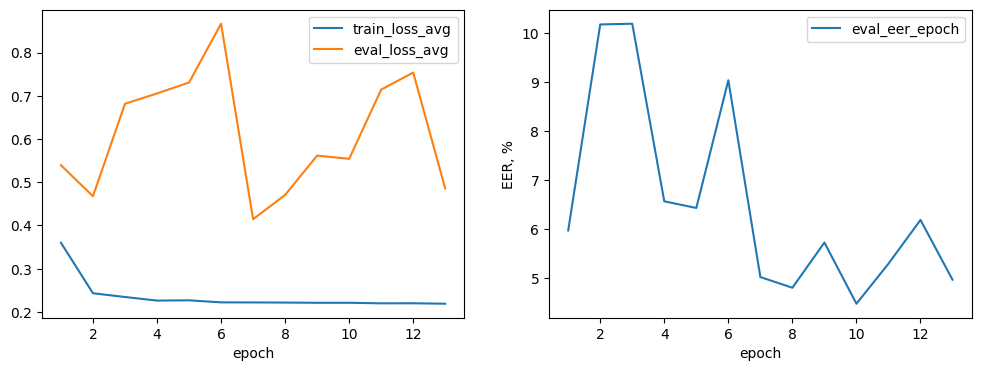

In [32]:
import wandb
import matplotlib.pyplot as plt

REPORT_DIR = Path("/kaggle/working/report")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

run = wandb.Api().run(current_run_path)
epoch_history = run.history(keys=["epoch", "train_loss_avg", "eval_loss_avg", "eval_eer_epoch"])
step_history = run.history(keys=["train_loss_step", "lr"])

epoch_history.to_csv(REPORT_DIR / "wandb_epoch_history.csv", index=False)
step_history.to_csv(REPORT_DIR / "wandb_step_history.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epoch_history["epoch"], epoch_history["train_loss_avg"], label="train_loss_avg")
axes[0].plot(epoch_history["epoch"], epoch_history["eval_loss_avg"], label="eval_loss_avg")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].plot(epoch_history["epoch"], epoch_history["eval_eer_epoch"], label="eval_eer_epoch")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("EER, %")
axes[1].legend()

fig.savefig(REPORT_DIR / "train_eval_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## Result

In [33]:
best_checkpoint = Path(config.checkpoint_dir) / "checkpoint_best.pt"
best_epoch, monitor_eer_at_best, best_eval_eer = load_checkpoint(
    model, optimizer=None, scheduler=None, path=best_checkpoint, device=config.device
)
print(f"Loaded {best_checkpoint.name}: epoch {best_epoch}, monitor eval_eer_epoch {monitor_eer_at_best:.5f}%")

eval_loss_avg_final, eval_eer_final, eval_threshold_final, predictions_df = evaluate(
    model, eval_loader, criterion, config, verbose=True
)

print(f"\nFINAL eval EER (full eval set): {eval_eer_final:.5f}%")
print(f"eval_loss_avg_final:  {eval_loss_avg_final:.5f}")
print(f"eval_threshold_final: {eval_threshold_final:.5f}")

eval_scores_df = eval_df.merge(predictions_df, on="audio_filename")
eval_scores_df.head()

Loaded checkpoint_best.pt: epoch 10, monitor eval_eer_epoch 4.47351%


Evaluating:   0%|          | 0/8905 [00:00<?, ?it/s]


FINAL eval EER (full eval set): 4.47351%
eval_loss_avg_final:  0.55414
eval_threshold_final: 2.68923


,speaker_id,audio_filename,system_id,key,target,score
0,LA_0039,LA_E_2834763,A11,spoof,1,-0.742464
1,LA_0014,LA_E_8877452,A14,spoof,1,-3.106485
2,LA_0040,LA_E_6828287,A16,spoof,1,-3.044675
3,LA_0022,LA_E_6977360,A09,spoof,1,-2.641128
4,LA_0031,LA_E_5932896,A13,spoof,1,-1.162267


In [34]:
UNIVERSITY_EMAIL = "masudarikova"
SUBMISSION_PATH = Path("/kaggle/working") / f"{UNIVERSITY_EMAIL}.csv"

eval_scores_df[["audio_filename", "score"]].to_csv(SUBMISSION_PATH, index=False, header=False)
print(f"Saved {len(eval_scores_df)} predictions in {SUBMISSION_PATH}")

Saved 71237 predictions in /kaggle/working/masudarikova.csv


## Grading check

In [35]:
import shutil

SCRIPTS_DIR = Path("/kaggle/input/datasets/sudarikovamaria")
GRADING_DIR = Path("/kaggle/working/grading_check")
SOLUTIONS_DIR = GRADING_DIR / "students_solutions"
SOLUTIONS_DIR.mkdir(parents=True, exist_ok=True)

shutil.copy(SCRIPTS_DIR / "grading-py/grading.py", GRADING_DIR)
shutil.copy(SCRIPTS_DIR / "calculate-eer/calculate_eer.py", GRADING_DIR)
shutil.copy(protocol_path["eval"], GRADING_DIR / "ASVspoof2019.LA.cm.eval.trl.txt")
shutil.copy(SUBMISSION_PATH, SOLUTIONS_DIR)

print("grading_check ready:", sorted(p.name for p in GRADING_DIR.iterdir()))

grading_check ready: ['ASVspoof2019.LA.cm.eval.trl.txt', 'calculate_eer.py', 'grading.py', 'students_solutions']


In [36]:
!cd /kaggle/working/grading_check && python3 grading.py

Grading complete. Results saved to /kaggle/working/grading_check/grades.csv


In [37]:
import pandas as pd

grades = pd.read_csv("/kaggle/working/grading_check/grades.csv")
display(grades)

,name,email,eer,grade
0,masudarikova,masudarikova@edu.hse.ru,4.4735,10
